# Task 3

## Setup: Imports, Dependencies and Paths

In [1]:
%pip install torch torchvision --index-url https://download.pytorch.org/whl/cu126
%pip install roboflow ultralytics pandas
%pip install scikit-image

Looking in indexes: https://download.pytorch.org/whl/cu126
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.2/41.2 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 250.0/250.0 kB 11.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 19.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 61.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.2/53.2 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 60.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 112.1 MB/s eta 0:00:00
  Attempting uninstall: opencv-python-headless
    Found existing installation: opencv-python-headless 4.13.0.92
    Uninstalling opencv-python-headless-4.13.0.92:
      Successfully uninstalled opencv-python-headless-4.13.0.92
  Attempting uninstall: idna
    Found existing installation: idna 3.18
    Uninstall

In [2]:
import json
import os
import random
import shutil
from pathlib import Path
import numpy as np
import pandas as pd
import yaml
import cv2
import zipfile
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torchvision.transforms import v2 as transforms
from ultralytics import YOLO, RTDETR
from scipy.spatial.distance import cdist
from scipy.optimize import linear_sum_assignment

%matplotlib inline

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In the next step, we will download the necessary data in order to train and evaluate the models:
- `Part1` folder for Part 1 (contains the pretrained models, and the roboflow dataset)
- `VC_data` for Part 2 (contains the pretrained, the roboflow dataset and a `partition.csv`)

Both datasets are from https://universe.roboflow.com/bachelorthesis/8-ball-pool-l530o/dataset/3.

In [3]:
# Flags for whether we want to train the models or not (might take some time if enabled)
TRAIN_PART_1 = False
TRAIN_PART_2 = False

# Root Folder
HERE = Path('/content')

# Content folder IDs
PART_1_ID = "1AX9JUxchliD4bs765SuyJgqMxmwN4VcI"
PART_2_ID = "1-gHrMp7TZyHm91HHKD8GzJHHkCkO5va0"

# Zip paths
ZIP_PATH_1 = 'Part1.zip'
ZIP_PATH_2 = 'VC_data.zip'

# Folders for part 1 and 2
DATASET_DIR_PART_1 = Path('/content/Part1')
DATASET_DIR_PART_2 = Path('/content/VC_data')

if not os.path.exists(ZIP_PATH_1):
    !gdown --id {PART_1_ID} -O {ZIP_PATH_1}

if not os.path.exists(ZIP_PATH_2):
    !gdown --id {PART_2_ID} -O {ZIP_PATH_2}

if not os.path.exists(DATASET_DIR_PART_1):
    with zipfile.ZipFile(ZIP_PATH_1, 'r') as zip_ref:
        zip_ref.extractall(DATASET_DIR_PART_1)

if not os.path.exists(DATASET_DIR_PART_2):
    with zipfile.ZipFile(ZIP_PATH_2, 'r') as zip_ref:
        zip_ref.extractall(DATASET_DIR_PART_2)

/usr/local/lib/python3.12/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1AX9JUxchliD4bs765SuyJgqMxmwN4VcI
From (redirected): https://drive.google.com/uc?id=1AX9JUxchliD4bs765SuyJgqMxmwN4VcI&confirm=t&uuid=8c0d78be-c57a-4409-9f5f-5d2515294457
To: /content/Part1.zip
100% 275M/275M [00:05<00:00, 47.5MB/s]
/usr/local/lib/python3.12/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1-gHrMp7TZyHm91HHKD8GzJHHkCkO5va0
From (redirected): https://drive.google.com/uc?id=1-gHrMp7TZyHm91HHKD8GzJHHkCkO5va0&confirm=t&uuid=2cbea941-a14a-4fbb-93c3-62cf28ef9933
To: /content/VC_data.zip
100% 

Next we define the necessary paths and set a seed to ensure reproducibility:

In [4]:
# fixed seed for reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

# Paths for Part 1
DATA_YAML_PART_1 = DATASET_DIR_PART_1 / "data.yaml"
MODEL_PT = DATASET_DIR_PART_1 / "model.pt" # where we keep the best weights
RUNS_DIR = DATASET_DIR_PART_1 / "runs"

# Paths for Part 2
yaml_path = os.path.join(DATASET_DIR_PART_2, '8-Ball-Pool-3/data.yaml') # TODO: Remove?
csv_path = os.path.join(DATASET_DIR_PART_2, 'partition.csv') # TODO: Change this to the actual partition CSV file path
roboflow_dir = DATASET_DIR_PART_2 / '8-Ball-Pool-3'
train_img_dir = os.path.join(roboflow_dir, 'train/images')
train_lbl_dir = os.path.join(roboflow_dir, 'train/labels')
val_img_dir = os.path.join(roboflow_dir, 'valid/images')
val_lbl_dir = os.path.join(roboflow_dir, 'valid/labels')
trained_model_path = DATASET_DIR_PART_2 / 'best.pt'

# Check directories
print("Working directory:", HERE)
print("Dataset for part 1 directory:", DATASET_DIR_PART_1)
print("Dataset for part 2 directory:", DATASET_DIR_PART_2)

# device: '0' for first GPU, 'cpu' otherwise
device = "0" if torch.cuda.is_available() else "cpu"
print("using device:", device)


Working directory: /content
Dataset for part 1 directory: /content/Part1
Dataset for part 2 directory: /content/VC_data
using device: cpu


## Part 1 - Ball Detection on 8-Ball Pool Table Images

### 1.1 Data Preparation

The dataset is already in YOLOv8 format, with `images/` and `labels/` folders and a train/valid/test split. The only adaptation needed is on the labels: the export ships five classes alphabetically (`Black`, `Cue`, `Dot`, `Solid`, `Striped`), so we drop the `Dot` annotations and remap the remaining class ids into the fixed `CLASS_NAMES` order, then write a four-class `data.yaml`.

In [5]:
# Define class names and mapping
CLASS_NAMES = ["cue", "solid", "striped", "black"]
NAME_TO_CLASS = {"cue": 0, "solid": 1, "striped": 2, "black": 3}

# Check if data.yaml already lists the four classes
names = [str(n) for n in yaml.safe_load(DATA_YAML_PART_1.read_text())["names"]]
if names == CLASS_NAMES:
    print("data.yaml already lists the four classes; nothing to do")
else:
    # map each source class id -> our class id (ids not in the map are dropped)
    remap = {i: NAME_TO_CLASS[n.lower()] for i, n in enumerate(names) if n.lower() in NAME_TO_CLASS}

    # rewrite every label file: drop dropped-class lines and remap the kept ones
    for split in ("train", "valid", "test"):
        for label_file in (DATASET_DIR_PART_1 / split / "labels").glob("*.txt"):
            lines = []
            for line in label_file.read_text().splitlines():
                parts = line.split()
                if parts and int(parts[0]) in remap:
                    lines.append(" ".join([str(remap[int(parts[0])]), *parts[1:]]))
            label_file.write_text("\n".join(lines))

    # write a 4-class data.yaml
    DATA_YAML_PART_1.write_text(
        f"path: {DATASET_DIR_PART_1.resolve()}\n"
        "train: train/images\nval: valid/images\ntest: test/images\n"
        f"nc: {len(CLASS_NAMES)}\nnames: {CLASS_NAMES}\n"
    )
    print("dataset remapped to 4 classes")

dataset remapped to 4 classes


### 1.2 Build and Fine-Tune the Detectors

In this step, we **define the network from its architecture file** (the `.yaml` that describes the layers) and then **load the pretrained weights published by Ultralytics** into it.

We train and compare the following detectors:
- **YOLOv8n** and **YOLOv8s**: the nano and small variants of YOLOv8 (one-stage, anchor-free CNN detectors). Comparing the two shows the accuracy/speed trade-off of model size.
- **RT-DETR-L**: a real-time DETR (transformer-based) detector.

All models share the same hyperparameters so the comparison is fair.

In [6]:
# hyperparameters
model_name = "yolov8n.pt"
epochs = 100
imgsz = 832
batch = 4

# architectures to compare
ARCHITECTURES = {
    "yolov8n": ("yolov8n.yaml", "yolov8n.pt"), # YOLOv8 nano variant
    "yolov8s": ("yolov8s.yaml", "yolov8s.pt"), # YOLOv8 small variant
    "rtdetr-l": ("rtdetr-l.yaml", "rtdetr-l.pt") # Real-time DETR (transformer-based)
}

def build_model(arch_yaml: str, weights: str):
    """Build a detector from its architecture file and load pretrained Ultralytics weights"""
    cls = RTDETR if "rtdetr" in arch_yaml else YOLO
    return cls(arch_yaml).load(weights)

In [7]:
best_weights = {}
if TRAIN_PART_1: # Only train if flag is enabled
    for name, (arch_yaml, weights) in ARCHITECTURES.items():
        print(f"\n===== training {name} =====")
        model = build_model(arch_yaml, weights)
        model.train(
            data=str(DATA_YAML_PART_1),
            epochs=epochs, imgsz=imgsz, batch=batch, device=device,
            seed=42, project=str(RUNS_DIR), name=name, exist_ok=True,
        )
        best_weights[name] = Path(model.trainer.best)
        print(f"{name} best weights: {best_weights[name]}")

else:
    # not training -> reuse the checkpoints saved from a previous run
    for name in ARCHITECTURES:
        ckpt = RUNS_DIR / name / "weights" / "best.pt" # same path train() wrote to
        if not ckpt.exists():
            raise FileNotFoundError(f"no saved weights for {name}: {ckpt}")
        best_weights[name] = ckpt
        print(f"{name} loaded weights: {ckpt}")

yolov8n loaded weights: /content/Part1/runs/yolov8n/weights/best.pt
yolov8s loaded weights: /content/Part1/runs/yolov8s/weights/best.pt
rtdetr-l loaded weights: /content/Part1/runs/rtdetr-l/weights/best.pt


### 1.3 Evaluate and Compare Architectures

In [8]:
def load_model(name: str, weights):
    """Reload a trained detector with the right class for its architecture."""
    cls = RTDETR if "rtdetr" in name else YOLO
    return cls(str(weights))


# evaluate every trained model on the test split
comparison = {}
for name, weights in best_weights.items():
    m = load_model(name, weights)
    metrics = m.val(data=str(DATA_YAML_PART_1), imgsz=imgsz, device=device, split="test", verbose=False)
    comparison[name] = {
        "map50": float(metrics.box.map50),
        "map": float(metrics.box.map),
        "ap50": {cn: float(metrics.box.ap50[i]) for i, cn in enumerate(CLASS_NAMES)},
        "speed_ms": float(metrics.speed["inference"]),
    }

# print a comparison table
header = f"{'model':<10} {'mAP@0.5':>8} {'mAP@.5:.95':>11} {'ms/img':>7}   " + "  ".join(f"{c:>7}" for c in CLASS_NAMES)
print(header)
print("-" * len(header))
for name, r in comparison.items():
    per_class = "  ".join(f"{r['ap50'][c]:>7.3f}" for c in CLASS_NAMES)
    print(f"{name:<10} {r['map50']:>8.3f} {r['map']:>11.3f} {r['speed_ms']:>7.1f}   {per_class}")

# pick the best model by mAP@0.5:0.95 and keep its weights as the final detector
BEST_NAME = max(comparison, key=lambda n: comparison[n]["map"])
shutil.copy2(best_weights[BEST_NAME], MODEL_PT)
print(f"\nbest model: {BEST_NAME} -> copied to {MODEL_PT}")

# the final detector reused by the prediction step below
model = load_model(BEST_NAME, MODEL_PT)

Ultralytics 8.4.78 🚀 Python-3.12.13 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLOv8n summary (fused): 73 layers, 3,006,428 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1118.8±322.7 MB/s, size: 128.2 KB)
val: Scanning /content/Part1/test/labels... 20 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 20/20 337.7it/s 0.1s
val: New cache created: /content/Part1/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 3.9s/it 7.8s
                   all         20        226       0.97      0.919       0.96      0.823
Speed: 23.0ms preprocess, 337.0ms inference, 0.0ms loss, 2.1ms postprocess per image
Results saved to /content/runs/detect/val
Ultralytics 8.4.78 🚀 Python-3.12.13 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLOv8s summary (fused): 73 layers, 11,127,132 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1692.5±181.5 

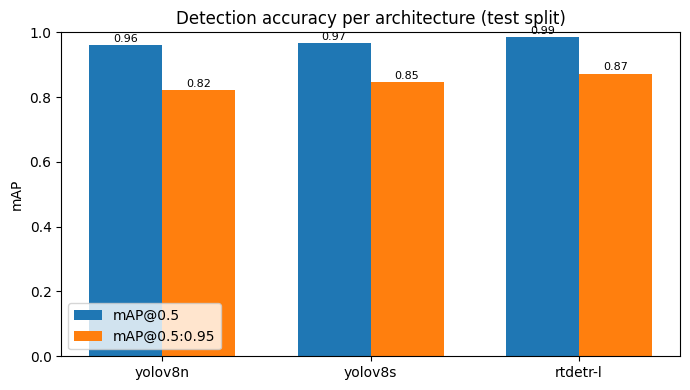

In [9]:
# bar chart comparing the architectures (handy for the report)
names = list(comparison)
x = np.arange(len(names))
width = 0.35

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(x - width / 2, [comparison[n]["map50"] for n in names], width, label="mAP@0.5")
ax.bar(x + width / 2, [comparison[n]["map"] for n in names], width, label="mAP@0.5:0.95")
ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylabel("mAP")
ax.set_ylim(0, 1)
ax.set_title("Detection accuracy per architecture (test split)")
ax.legend()
for i, n in enumerate(names):
    ax.text(i - width / 2, comparison[n]["map50"] + 0.01, f"{comparison[n]['map50']:.2f}", ha="center", fontsize=8)
    ax.text(i + width / 2, comparison[n]["map"] + 0.01, f"{comparison[n]['map']:.2f}", ha="center", fontsize=8)
plt.tight_layout()
plt.show()

### 1.4 Predict

Run detection over the images listed in an input JSON and write detections.

In [10]:
conf = 0.5 # confidence threshold for predictions

# load the images to predict on directly from the dataset's test split
image_paths = sorted(str(p) for p in (DATASET_DIR_PART_1 / "test" / "images").glob("*.jpg"))

# predict on all images at once
results = model.predict(image_paths, conf=conf, device=device, verbose=False)

# build the output JSON and save the annotated images
out_dir = DATASET_DIR_PART_1 / "predictions_part1"
out_dir.mkdir(exist_ok=True)

records = []
for entry, result in zip(image_paths, results):
    result.save(filename=str(out_dir / os.path.basename(entry)))

Show some predictions:

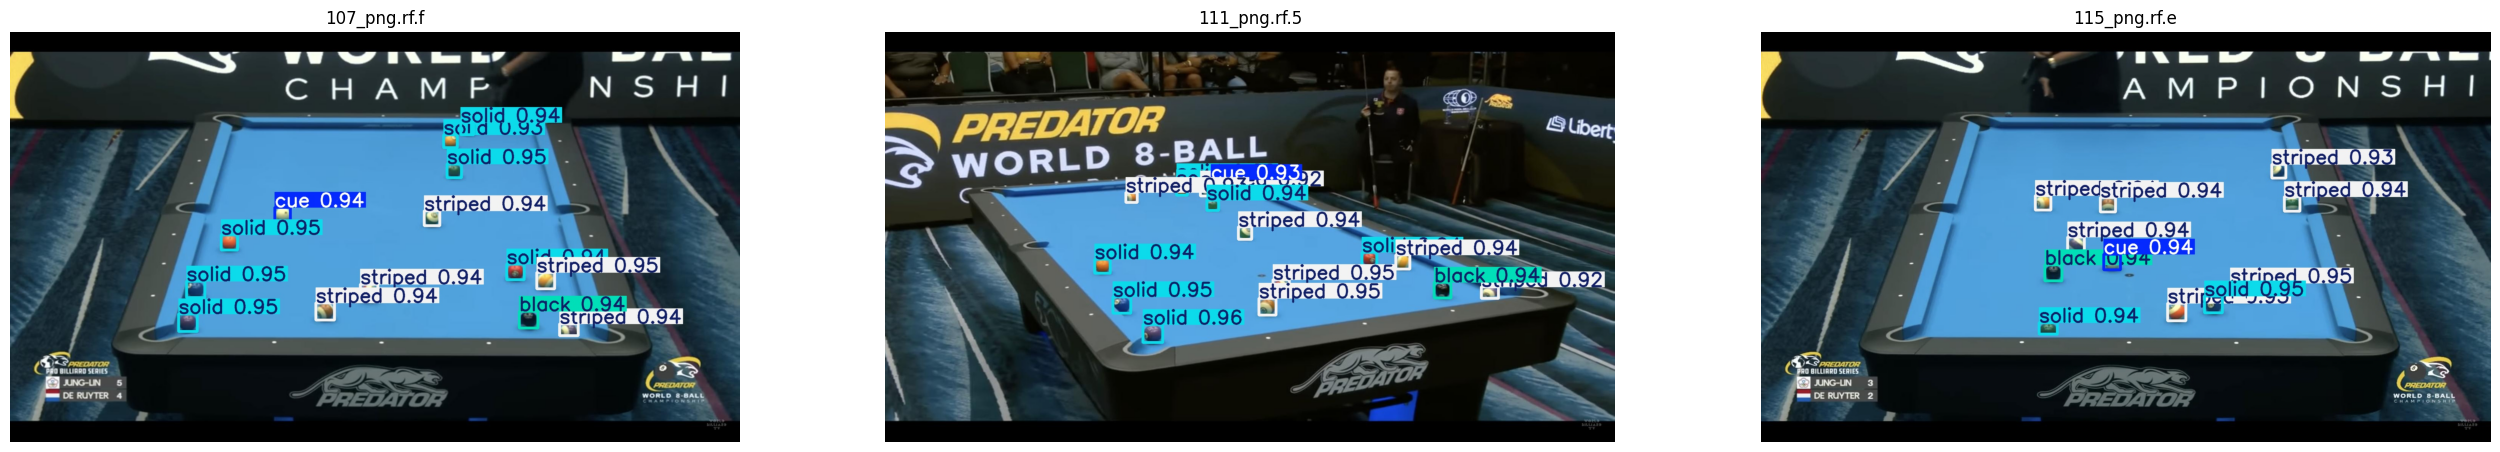

In [11]:
# Show the first N_SHOW predictions
N_SHOW = 3
saved = sorted(out_dir.glob("*.jpg"))[:N_SHOW]
f, axarr = plt.subplots(1, N_SHOW, figsize=(32, 10))
for i, path in enumerate(saved):
    img = plt.imread(path)
    axarr[i].imshow(img, vmin=0, vmax=255)
    axarr[i].set_title(path.name[:12])
    axarr[i].axis("off")

## Part 2 - Table Retrieval

Table retrieval relies on its own dataset and a custom detector (`best.pt`) that also detects the table `Dot`s, which the homography step needs, unlike Part 1's `model.pt`, whose labels drop the `Dot` class.

### 2.1 Data Loading and Dataset

In [12]:
os.makedirs(val_img_dir, exist_ok=True)
os.makedirs(val_lbl_dir, exist_ok=True)

df = pd.read_csv(csv_path)

val_images = df[df['partition'] == 'valid']['image_name'].values
for img_name in val_images:
    base_name = os.path.splitext(img_name)[0]
    lbl_name = f"{base_name}.txt"

    src_img = os.path.join(train_img_dir, img_name)
    src_lbl = os.path.join(train_lbl_dir, lbl_name)

    if os.path.exists(src_img):
        shutil.move(src_img, os.path.join(val_img_dir, img_name))
        if os.path.exists(src_lbl):
            shutil.move(src_lbl, os.path.join(val_lbl_dir, lbl_name))

print("csv_path:", csv_path)
print("roboflow_dir:", roboflow_dir)

csv_path: /content/VC_data/partition.csv
roboflow_dir: /content/VC_data/8-Ball-Pool-3


In [13]:
if (TRAIN_PART_2): # Only train model if flag enabled
  model = YOLO('yolov8x.pt')

  model.train(
      data=yaml_path,
      epochs=30,
      imgsz=1280,
      batch=4,
      device=device,
      verbose=True
  )

In [14]:
class PoolDataset:
    def __init__(self, root, partition_file, partition, transform=None):
        self.root = root
        partition_file = pd.read_csv(partition_file)

        idx = np.where(np.asarray(partition_file['partition'].values) == partition)[0]
        self.files = np.asarray(partition_file['image_name'].values)[idx]
        self.transform = transform

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        img_path = os.path.join(self.root, self.files[idx])
        img = Image.open(img_path).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img

    def get_raw_image(self, idx):
        img_path = os.path.join(self.root, self.files[idx])
        return Image.open(img_path).convert('RGB')

In [15]:
val_transform = transforms.Compose([
    transforms.ToImage(),
    transforms.Resize((256, 256)),
    transforms.CenterCrop((224, 224)),
    transforms.ToDtype(torch.float32, True),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

images_path = os.path.join(DATASET_DIR_PART_2, '8-Ball-Pool-3/train/images')
partition_csv_path = os.path.join(DATASET_DIR_PART_2, 'partition.csv')

retrieval_pool = PoolDataset(images_path, partition_csv_path, 'train', val_transform)
query_data = PoolDataset(images_path, partition_csv_path, 'test', val_transform)

print(f"Dataset successfully loaded!")
print(f"Images in Retrieval Pool (Train): {len(retrieval_pool)}")
print(f"Images in Query Data (Test): {len(query_data)}")

Dataset successfully loaded!
Images in Retrieval Pool (Train): 207
Images in Query Data (Test): 20


### 2.2 Semantic Object Detection (YOLO)

First, we load the custom YOLO model:

In [16]:
# custom detector that ALSO detects table dots (needed for the
# homography below); Part 1's model.pt drops the Dot class
model_custom = YOLO(trained_model_path)

def extract_table_state(pil_image, box_threshold=0.10):
    """ Uses custom YOLO to find pool balls and table dots/diamonds simultaneously."""
    results = model_custom(pil_image, conf=box_threshold, imgsz=1280, device=device, verbose=False)[0]

    balls_centers = []
    dots_centers = []

    class_names = results.names

    for box in results.boxes:
        cls_id = int(box.cls[0].item())
        class_name = class_names[cls_id].lower()

        xc, yc, _, _ = box.xywh[0].cpu().numpy()

        if class_name == 'dot':
            dots_centers.append([xc, yc])
        else:
            balls_centers.append([xc, yc])

    return np.array(balls_centers), np.array(dots_centers)

Geometric Utilities and Point Ordering:

In [17]:
def order_points(pts):
    """
    Robust geometric ordering for extreme oblique perspectives using radial angles.
    Ensures order: Top-Left, Top-Right, Bottom-Right, Bottom-Left.
    """
    pts = np.array(pts, dtype="float32")
    center = np.mean(pts, axis=0)
    angles = np.arctan2(pts[:, 1] - center[1], pts[:, 0] - center[0])
    sorted_indices = np.argsort(angles)
    return pts[sorted_indices]

def dist_to_segment(p, a, b):
    ab = b - a
    norm_sq = np.dot(ab, ab)
    if norm_sq < 1e-8:
        return np.linalg.norm(p - a)
    ap = p - a
    t = np.clip(np.dot(ap, ab) / norm_sq, 0.0, 1.0)
    projection = a + t * ab
    return np.linalg.norm(p - projection)

RANSAC Algorithm for Rail Line Extraction:

In [18]:
def extract_best_line_ransac(points, threshold=6, iterations=1000):
    best_inliers = []
    if len(points) < 2:
        return None, [], points

    for _ in range(iterations):
        idx = np.random.choice(len(points), 2, replace=False)
        p1, p2 = points[idx[0]], points[idx[1]]
        if np.linalg.norm(p1 - p2) < 1e-5: continue

        a = p2[1] - p1[1]
        b = p1[0] - p2[0]
        c = p2[0]*p1[1] - p2[1]*p1[0]

        norm = np.hypot(a, b)
        if norm == 0: continue
        a, b, c = a/norm, b/norm, c/norm

        distances = np.abs(a * points[:, 0] + b * points[:, 1] + c)
        inliers = np.where(distances <= threshold)[0]

        if len(inliers) > len(best_inliers):
            best_inliers = inliers

    if len(best_inliers) < 2:
        return None, [], points

    inlier_points = points[best_inliers]
    remaining_points = np.delete(points, best_inliers, axis=0)

    vx, vy, x0, y0 = cv2.fitLine(np.float32(inlier_points), cv2.DIST_L2, 0, 0.01, 0.01)
    a, b = float(vy[0]), float(-vx[0])
    c = float(vy[0] * x0[0] - vx[0] * y0[0])
    return (a, b, c), inlier_points, remaining_points

Table Homography Matrix Estimation:

In [19]:
def get_table_homography(dots_centers, target_width=800, target_height=400):
    if len(dots_centers) < 4:
        return None, None, None

    W, H = max(target_width, target_height), min(target_width, target_height)
    lines = []
    remaining = dots_centers.copy()

    for _ in range(4):
        line, inliers, remaining = extract_best_line_ransac(remaining, threshold=6, iterations=1000)
        if line is not None:
            lines.append(line)

    corners = []

    if len(lines) == 4:
        raw_intersections = []
        for i in range(4):
            for j in range(i+1, 4):
                a1, b1, c1 = lines[i]
                a2, b2, c2 = lines[j]

                D = a1 * b2 - b1 * a2
                if abs(D) > 1e-5:
                    x = (c1 * b2 - b1 * c2) / D
                    y = (a1 * c2 - c1 * a2) / D
                    raw_intersections.append([x, y])

        unique_intersections = []
        for pt in raw_intersections:
            if not any(np.linalg.norm(np.array(pt) - np.array(u)) < 15 for u in unique_intersections):
                unique_intersections.append(pt)

        if len(unique_intersections) >= 4:
            table_center = np.mean(dots_centers, axis=0)

            max_dist_allowed = np.max(np.linalg.norm(dots_centers - table_center, axis=1)) * 2.0
            valid_intersections = [pt for pt in unique_intersections if np.linalg.norm(pt - table_center) < max_dist_allowed]

            if len(valid_intersections) >= 4:
                valid_intersections = np.array(valid_intersections)
                distances = np.linalg.norm(valid_intersections - table_center, axis=1)
                best_corners = valid_intersections[np.argsort(distances)[:4]]
                corners = order_points(np.float32(best_corners))

    if len(corners) != 4:
        return None, None, None

    rails = {'horizontal': 0, 'vertical': 0}
    for pt in dots_centers:
        d_top = dist_to_segment(pt, corners[0], corners[1])
        d_bottom = dist_to_segment(pt, corners[3], corners[2])
        d_left = dist_to_segment(pt, corners[0], corners[3])
        d_right = dist_to_segment(pt, corners[1], corners[2])

        closest = np.argmin([d_top, d_bottom, d_left, d_right])
        if closest in [0, 1]: rails['horizontal'] += 1
        else: rails['vertical'] += 1

    if rails['horizontal'] >= rails['vertical']:
        src_pts = corners
        dst_pts = np.array([[0, 0], [W, 0], [W, H], [0, H]], dtype=np.float32)
    else:
        src_pts = np.array([corners[3], corners[0], corners[1], corners[2]], dtype=np.float32)
        dst_pts = np.array([[0, 0], [W, 0], [W, H], [0, H]], dtype=np.float32)

    H_matrix, _ = cv2.findHomography(src_pts, dst_pts)
    return H_matrix, (W, H), corners

Perspective Transformation and Spatial Normalization [0, 1]

In [20]:
def transform_and_normalize_balls(original_balls, H_matrix, target_dims):
    """
    Translates ball coordinates to top-down view and normalizes to [0, 1].
    """
    if len(original_balls) == 0 or H_matrix is None:
        return []

    pts_formatted = np.array(original_balls, dtype=np.float32).reshape(-1, 1, 2)

    pts_warped = cv2.perspectiveTransform(pts_formatted, H_matrix)
    pts_topdown = pts_warped.reshape(-1, 2)

    W, H = target_dims
    normalized_balls = []

    for x, y in pts_topdown:
        norm_x = np.clip(x / W, 0.0, 1.0)
        norm_y = np.clip(y / H, 0.0, 1.0)

        normalized_balls.append([round(norm_x, 4), round(norm_y, 4)])

    return normalized_balls

Processing and Database Creation (Train Pool)

In [ ]:
retrieval_database = []

print(f"Indexing {len(retrieval_pool)} training pool images... Please wait.")

for idx in range(len(retrieval_pool)):
    img_pil = retrieval_pool.get_raw_image(idx)

    balls_centers, dots_centers = extract_table_state(img_pil, box_threshold=0.10)

    if len(dots_centers) >= 4:
        H_matrix, target_dims, corners = get_table_homography(dots_centers, target_width=800, target_height=400)

        if H_matrix is None or H_matrix.shape != (3, 3) or np.linalg.det(H_matrix) == 0:
            continue

        final_game_state = transform_and_normalize_balls(balls_centers, H_matrix, target_dims)

        retrieval_database.append({
            "image_index": idx,
            "ball_count": len(final_game_state),
            "state": final_game_state
        })

    if idx % 50 == 0 and idx > 0:
        print(f"Processed {idx}/{len(retrieval_pool)} images...")

print(f"Done! Database successfully generated with {len(retrieval_database)} signatures ready.")

Indexing 207 training pool images... Please wait.


State Distance Calculation via Hungarian Algorithm

In [ ]:
def calculate_state_distance(query_state, candidate_state, penalty_weight=1.0):
    """
    Calculates the similarity (distance) between two pool table states.
    Lower score = more similar. 0 = exact match.
    """

    if len(query_state) == 0 and len(candidate_state) == 0:
        return 0.0
    if len(query_state) == 0:
        return len(candidate_state) * penalty_weight
    if len(candidate_state) == 0:
        return len(query_state) * penalty_weight

    cost_matrix = cdist(query_state, candidate_state, metric='euclidean')

    row_ind, col_ind = linear_sum_assignment(cost_matrix)

    matched_distance = cost_matrix[row_ind, col_ind].sum()

    num_unmatched = abs(len(query_state) - len(candidate_state))
    total_cost = matched_distance + (num_unmatched * penalty_weight)

    return total_cost

def retrieve_similar_images(query_state, database, query_index, top_k=5):
    """
    Searches the database and ignores the query image itself.
    """
    results = []

    for entry in database:
        if entry["image_index"] == query_index:
            continue

        cand_state = entry["state"]
        distance_score = calculate_state_distance(query_state, cand_state, penalty_weight=0.5)

        results.append({
            "image_index": entry["image_index"],
            "ball_count": entry["ball_count"],
            "distance": distance_score
        })

    results = sorted(results, key=lambda x: x["distance"])
    return results[:top_k]

### 2.3 Results Evaluation

In [ ]:
for query_index in range(len(query_data)):

    current_query_img_pil = query_data.get_raw_image(query_index)
    current_query_img_np = np.array(current_query_img_pil)
    current_balls_centers, current_dots_centers = extract_table_state(current_query_img_pil, box_threshold=0.10)

    if len(current_dots_centers) < 4:
        print(f"Index {query_index}: Not enough dots ({len(current_dots_centers)}). Skipping.")
        continue

    current_H_matrix, current_target_dims, current_corners = get_table_homography(current_dots_centers, target_width=800, target_height=400)

    if current_H_matrix is None or current_H_matrix.shape != (3, 3) or np.linalg.det(current_H_matrix) == 0:
        print(f"Index {query_index}: Invalid homography. Skipping.")
        continue

    current_query_state = transform_and_normalize_balls(current_balls_centers, current_H_matrix, current_target_dims)

    top_matches = retrieve_similar_images(current_query_state, retrieval_database, query_index, top_k=5);

    if len(top_matches) >= 5:
        print(f"\n=================== RESULTS FOR QUERY INDEX {query_index} ===================")

        f, axarr = plt.subplots(2, 6, figsize=(22, 8))
        W, H = current_target_dims

        axarr[0, 0].imshow(current_query_img_np)
        axarr[0, 0].scatter(current_dots_centers[:, 0], current_dots_centers[:, 1], color='cyan', s=15, edgecolors='black')
        axarr[0, 0].set_title(f"QUERY Original (#{query_index})", fontweight='bold', color='darkblue')
        axarr[0, 0].axis("off")

        warped_query = cv2.warpPerspective(current_query_img_np, current_H_matrix, (W, H))
        axarr[1, 0].imshow(warped_query)
        if len(current_query_state) > 0:
            state_np = np.array(current_query_state)
            axarr[1, 0].scatter(state_np[:, 0] * W, state_np[:, 1] * H, color='cyan', s=40, edgecolors='black', zorder=5)
        axarr[1, 0].set_title("QUERY Warped", color='darkblue')
        axarr[1, 0].axis("off")

        for j in range(1, 6):
            match = top_matches[j-1]
            match_idx = match["image_index"]

            cand_img_pil = retrieval_pool.get_raw_image(match_idx)
            cand_img_np = np.array(cand_img_pil)

            axarr[0, j].imshow(cand_img_np)
            axarr[0, j].set_title(f"Rank {j} (#{match_idx})", fontweight='bold')
            axarr[0, j].axis("off")

            cand_balls, cand_dots = extract_table_state(cand_img_pil, box_threshold=0.10)
            H_cand, dims_cand, _ = get_table_homography(cand_dots, target_width=800, target_height=400)

            if H_cand is not None:
                W_c, H_c = dims_cand
                warped_cand = cv2.warpPerspective(cand_img_np, H_cand, (W_c, H_c))
                axarr[1, j].imshow(warped_cand)

                cand_state = next(item for item in retrieval_database if item["image_index"] == match_idx)["state"]
                if len(cand_state) > 0:
                    cand_np = np.array(cand_state)
                    axarr[1, j].scatter(cand_np[:, 0] * W_c, cand_np[:, 1] * H_c, color='magenta', s=40, edgecolors='white', zorder=5)
            else:
                axarr[1, j].imshow(cand_img_np)

            axarr[1, j].set_title(f"Dist = {match['distance']:.4f}\nBalls = {match['ball_count']}")
            axarr[1, j].axis("off")

        plt.tight_layout()
        plt.show()
    else:
        print(f"Index {query_index}: Could not get enough results for the plot.")